# Chapter 95: Insurance, Education, Poverty, and Targeting

This notebook reruns four worked examples from the chapter: the smoothing gain against the duration response in unemployment insurance, ordeals that screen the right or wrong people, tags with errors, and crowd-out arithmetic. Every number is one of the chapter's hypothetical teaching values, not an estimate from a real program; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def baily_chetty_indices(gamma, ce, cu, D0, D1, db):
    """Smoothing index gamma (ce - cu) / ce against duration elasticity ((D1 - D0) / D0) / db.

    baily-chetty-optimal-unemployment-insurance-formula (chapter 95): drop 0.20, index 0.40, elasticity
    0.50; at cu = 2,100 index 0.60; at D1 = 10.2 elasticity 0.20.
    """
    drop = (ce - cu) / ce
    smooth = gamma * drop
    eps = ((D1 - D0) / D0) / db
    return {"drop": drop, "smooth": smooth, "eps": eps, "raise": smooth > eps, "tie": abs(smooth - eps) < 1e-12}


def ordeal_screen(values, burdens, n, package_cost):
    """Groups enroll iff value - burden >= 0; transfers n x package cost per enrolled group; ordeal cost n x burden.

    ordeal-mechanism (chapter 95): values 180 and 80, burden 100: high enrolls (80), low does not (-20);
    transfers 12,000, ordeal cost 10,000. Burdens 190 and 60: net -10 and 20.
    """
    net = [v - c for v, c in zip(values, burdens)]
    enroll = [x >= 0 for x in net]
    k = sum(enroll)
    return {"net": net, "enroll": enroll, "transfers": k * n * package_cost,
            "ordeal": sum(n * c for c, e in zip(burdens, enroll) if e)}


def tagging_outcomes(n_t, n_o, tpr, fpr, pay, base_pay):
    """Tag rule pays `pay` to true and false positives; income-only rule pays `base_pay` to everyone.

    akerlof-tagging-principle (chapter 95): 300 + 60 = 360 tagged, cost 2,880,000, target receipts
    2,400,000; income-only 4,000,000 and 1,600,000; at 40 percent false positives cost 4,320,000.
    """
    tp, fp = tpr * n_t, fpr * n_o
    return {"tp": tp, "fp": fp, "tagged": tp + fp, "cost": (tp + fp) * pay, "target": tp * pay,
            "base_cost": (n_t + n_o) * base_pay, "base_target": n_t * base_pay}


def crowd_out(parts_private, uninsured):
    """G = private switchers + uninsured take-up, P = private switchers, N = G - P, crowd-out P / G.

    public-insurance-crowd-out (chapter 95): G = 300 + 60 + 320 = 680, P = 360, N = 320, 0.529;
    with 180 and 40, G = 540, P = 220, 0.407.
    """
    P = sum(parts_private)
    G = P + uninsured
    return {"G": G, "P": P, "N": G - P, "rate": P / G if G else None, "net_share": (G - P) / G if G else None}


plt.rcParams.update(HOUSE_RC)


public = SimpleNamespace(baily_chetty_indices=baily_chetty_indices, ordeal_screen=ordeal_screen, tagging_outcomes=tagging_outcomes, crowd_out=crowd_out)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'baily-chetty-optimal-unemployment-insurance-formula': {'ce': 3000,
                                                         'cu': 2400,
                                                         'gamma': 2,
                                                         'drop': 0.2,
                                                         'smooth': 0.4,
                                                         'D0': 10,
                                                         'D1': 10.5,
                                                         'db': 0.1,
                                                         'eps': 0.5,
                                                         'cu_low': 2100,
                                                         'smooth_low': 0.6,
                                                         'D1_low': 10.2,
                                                         'eps_low': 0.2},
 'ordeal-mechanism': {'n': 100,
                      'v_high': 180,
                      'v_low': 80,
                      'package': 120,
                      'burden': 100,
                      'transfers_all': 24000,
                      'net_high': 80,
                      'net_low': -20,
                      'transfers': 12000,
                      'ordeal': 10000,
                      'burden_high': 190,
                      'burden_low': 60},
 'akerlof-tagging-principle': {'n_t': 400,
                               'n_o': 600,
                               'base_pay': 4000,
                               'pay': 8000,
                               'tpr': 0.75,
                               'fpr': 0.1,
                               'tp': 300,
                               'fp': 60,
                               'cost': 2880000,
                               'target': 2400000,
                               'base_cost': 4000000,
                               'base_target': 1600000,
                               'fpr_high': 0.4,
                               'cost_high': 4320000},
 'public-insurance-crowd-out': {'emp': 300,
                                'ind': 60,
                                'unin': 320,
                                'G': 680,
                                'P': 360,
                                'N': 320,
                                'rate': 0.529,
                                'net_share': 0.471,
                                'emp_low': 180,
                                'ind_low': 40,
                                'G_low': 540,
                                'P_low': 220,
                                'rate_low': 0.407},
 'constructed': {'baily-chetty-optimal-unemployment-insurance-formula': {'gamma': [1, 3]},
                 'ordeal-mechanism': {'burden_low': [190]},
                 'akerlof-tagging-principle': {'tpr': [0.5, 0.9], 'fpr': [0.25]},
                 'public-insurance-crowd-out': {'unin': [200]}}}


LABEL = "Hypothetical teaching values, not estimates from a real program."


def baily_picture(gamma=2, cu=2400, d1=10.5):
    r = public.baily_chetty_indices(gamma, 3000, cu, 10, d1, 0.10)
    fig, ax = new_figure()
    bar_compare(ax, ["Smoothing index", "Duration elasticity"], [r["smooth"], r["eps"]],
                colors=["teal", "terracotta"], value_labels=[num(r["smooth"]), num(r["eps"])],
                ylabel="Index", xlabel="Side of the formula")
    ax.set_ylim(0, 1.05)
    if r["tie"]:
        verdict, short = "the two sides are equal, so the current benefit is locally optimal", "Tie: keep benefit"
    elif r["raise"]:
        verdict, short = "the smoothing gain exceeds the behavioral cost, pointing toward a higher benefit", "Raise"
    else:
        verdict, short = "the behavioral cost exceeds the smoothing gain, pointing against a higher benefit", "Do not raise"
    metrics = {"Consumption drop": pct(r["drop"], 0), "Smoothing index": num(r["smooth"]),
               "Duration elasticity": num(r["eps"]), "Verdict": short}
    steps = [f"Drop = (3,000 - {num(cu, 0)}) / 3,000 = {num(r['drop'])}",
             f"Smoothing index = {gamma} x {num(r['drop'])} = {num(r['smooth'])}",
             f"Elasticity = (({num(d1, 1)} - 10) / 10) / 0.10 = {num(r['eps'])}",
             f"{num(r['smooth'])} against {num(r['eps'])}: {short.lower()}"]
    interp = (f"{LABEL} Consumption falls {pct(r['drop'], 0)} on unemployment, so with risk aversion {gamma} the "
              f"smoothing index is {gamma} x {num(r['drop'])} = {num(r['smooth'])}. A 10 percent benefit rise "
              f"lengthens duration to {num(d1, 1)} weeks, an elasticity of {num(r['eps'])}. In this local comparison "
              f"{verdict}.")
    alt = f"Two bars: smoothing index {num(r['smooth'])} and duration elasticity {num(r['eps'])}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ordeal_picture(ch=100, cl=100):
    b = BV["ordeal-mechanism"]
    r = public.ordeal_screen([b["v_high"], b["v_low"]], [ch, cl], b["n"], b["package"])
    fig, ax = new_figure()
    xs = np.arange(2)
    w = 0.36
    vals, burdens = [b["v_high"], b["v_low"]], [ch, cl]
    ax.bar(xs - w / 2, vals, w, color=PALETTE["teal"], label="Value of package")
    ax.bar(xs + w / 2, burdens, w, color=PALETTE["terracotta"], label="Ordeal burden")
    for x, v, c in zip(xs, vals, burdens):
        label(ax, x - w / 2, v, num(v, 0), dx=0, dy=3, ha="center", box=False)
        label(ax, x + w / 2, c, num(c, 0), dx=0, dy=3, ha="center", box=False)
    names = [f"High need: {'enrolls' if r['enroll'][0] else 'stays out'}",
             f"Low need: {'enrolls' if r['enroll'][1] else 'stays out'}"]
    ax.set_xticks(xs, names)
    ax.set_ylim(0, 260)
    ax.set_ylabel("Units per household")
    ax.set_xlabel("Group (100 households each)")
    ax.legend(loc="upper right", frameon=False, fontsize=10)
    hi, lo = r["enroll"]
    if hi and not lo:
        verdict = "the ordeal screens as intended"
    elif lo and not hi:
        verdict = "the ordeal screens the wrong way, admitting the low-need group and excluding the intended one"
    elif hi and lo:
        verdict = "both groups enroll, so the ordeal does not screen and only adds cost"
    else:
        verdict = "nobody enrolls"
    metrics = {"High-need net value": num(r["net"][0], 0), "Low-need net value": num(r["net"][1], 0),
               "Households enrolled": num(100 * sum(r["enroll"]), 0), "Transfers": num(r["transfers"], 0),
               "Ordeal cost borne": num(r["ordeal"], 0)}
    steps = [f"High need: 180 - {ch} = {num(r['net'][0], 0)}; low need: 80 - {cl} = {num(r['net'][1], 0)}",
             f"Transfers = {num(100 * sum(r['enroll']), 0)} x 120 = {num(r['transfers'], 0)}",
             f"Ordeal cost = " + (" + ".join(f"100 x {c}" for c, e in zip(burdens, r["enroll"]) if e) or "0")
             + f" = {num(r['ordeal'], 0)}"]
    interp = (f"{LABEL} With burdens of {ch} on high-need and {cl} on low-need households, net values are "
              f"180 - {ch} = {num(r['net'][0], 0)} and 80 - {cl} = {num(r['net'][1], 0)}, so {verdict}. Transfers are "
              f"{num(r['transfers'], 0)} and recipients bear {num(r['ordeal'], 0)} of ordeal cost.")
    alt = (f"Grouped bars: high need values the package at 180 against a burden of {ch}; low need at 80 against "
           f"{cl}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def tagging_picture(tpr=0.75, fpr=0.10):
    b = BV["akerlof-tagging-principle"]
    r = public.tagging_outcomes(b["n_t"], b["n_o"], tpr, fpr, b["pay"], b["base_pay"])
    fig, ax = new_figure()
    xs = np.arange(2)
    w = 0.36
    costs, targets = [r["base_cost"], r["cost"]], [r["base_target"], r["target"]]
    ax.bar(xs - w / 2, costs, w, color=PALETTE["grey"], label="Total cost")
    ax.bar(xs + w / 2, targets, w, color=PALETTE["teal"], label="Reaches constrained adults")
    for x, cst, tg in zip(xs, costs, targets):
        label(ax, x - w / 2, cst, num(cst / 1e6, 2) + "m", dx=0, dy=3, ha="center", box=False)
        label(ax, x + w / 2, tg, num(tg / 1e6, 2) + "m", dx=0, dy=3, ha="center", box=False)
    ax.set_xticks(xs, ["Income-only: 4,000 to all", "Tag: 8,000 to tagged"])
    ax.set_ylim(0, 6.6e6)
    ax.set_yticks([0, 1e6, 2e6, 3e6, 4e6, 5e6, 6e6], ["0", "1m", "2m", "3m", "4m", "5m", "6m"])
    ax.set_ylabel("Units")
    ax.set_xlabel("Rule")
    ax.legend(loc="upper center", ncol=2, frameon=False, fontsize=10)
    tp, fp = r["tp"], r["fp"]
    metrics = {"True positives": num(tp, 0), "False positives": num(fp, 0), "Tagged": num(r["tagged"], 0),
               "Tag cost": num(r["cost"], 0), "Target receipts": num(r["target"], 0),
               "Cost change vs income-only": f"{r['cost'] - r['base_cost']:+,.0f}"}
    steps = [f"True positives = {num(tpr)} x 400 = {num(tp, 0)}; false positives = {num(fpr)} x 600 = {num(fp, 0)}",
             f"Cost = {num(r['tagged'], 0)} x 8,000 = {num(r['cost'], 0)}",
             f"Target receipts = {num(tp, 0)} x 8,000 = {num(r['target'], 0)}",
             "Income-only: 1,000 x 4,000 = 4,000,000, of which 400 x 4,000 = 1,600,000 reaches the target"]
    interp = (f"{LABEL} The tag finds {num(tpr)} x 400 = {num(tp, 0)} constrained adults and wrongly admits "
              f"{num(fpr)} x 600 = {num(fp, 0)} others. Paying 8,000 to {num(r['tagged'], 0)} people costs {num(r['cost'], 0)}, of which "
              f"{num(r['target'], 0)} reaches the target, against 4,000,000 and 1,600,000 under the income-only rule.")
    alt = (f"Grouped bars: income-only costs 4.00m and delivers 1.60m to the target; the tag costs "
           f"{num(r['cost'] / 1e6)}m and delivers {num(r['target'] / 1e6)}m.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def crowd_picture(emp=300, ind=60, unin=320):
    r = public.crowd_out([emp, ind], unin)
    fig, ax = new_figure()
    ax.bar([0], [emp], color=PALETTE["navy"], width=0.55, label="From employer plans")
    ax.bar([0], [ind], bottom=[emp], color=PALETTE["gold"], width=0.55, label="From individual plans")
    ax.bar([0], [unin], bottom=[emp + ind], color=PALETTE["teal"], width=0.55, label="Previously uninsured")
    ax.bar([1], [r["N"]], color=PALETTE["teal"], width=0.55)
    label(ax, 0, r["G"], f"G = {num(r['G'], 0)}", dx=0, dy=4, ha="center", box=False)
    label(ax, 1, r["N"], f"N = {num(r['N'], 0)}", dx=0, dy=4, ha="center", box=False)
    ax.set_xticks([0, 1], ["Public enrollment G", "Net coverage gain N"])
    ax.set_xlim(-0.6, 2.4)
    ax.set_ylim(0, 820)
    ax.set_ylabel("Children")
    ax.set_xlabel("Measure")
    ax.legend(loc="upper right", frameon=False, fontsize=10)
    metrics = {"Public enrollment G": num(r["G"], 0), "Private loss P": num(r["P"], 0),
               "Net gain N": num(r["N"], 0), "Crowd-out P / G": num(r["rate"], 3),
               "Net gain per entrant": num(r["net_share"], 3)}
    steps = [f"G = {emp} + {ind} + {unin} = {num(r['G'], 0)}",
             f"P = {emp} + {ind} = {num(r['P'], 0)}",
             f"N = {num(r['G'], 0)} - {num(r['P'], 0)} = {num(r['N'], 0)}",
             f"Crowd-out = {num(r['P'], 0)} / {num(r['G'], 0)} = {num(r['rate'], 3)}"]
    interp = (f"{LABEL} Public enrollment is G = {emp} + {ind} + {unin} = {num(r['G'], 0)}, of which "
              f"{num(r['P'], 0)} left private plans, so net coverage rises by N = {num(r['N'], 0)} and crowd-out is "
              f"{num(r['P'], 0)} / {num(r['G'], 0)} = {num(r['rate'], 3)} ({pct(r['rate'])}). Public enrollment "
              f"alone would hide the displaced private coverage.")
    alt = (f"A stacked bar of public enrollment ({emp} from employer plans, {ind} from individual plans, {unin} "
           f"previously uninsured) next to the net gain of {num(r['N'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Baily-Chetty formula: smoothing gain versus duration response

Hypothetical values: consumption 3,000 employed and 2,400 unemployed, risk aversion 2, duration 10 weeks rising to 10.5 after a 10 percent benefit increase.

$$\frac{3{,}000-2{,}400}{3{,}000}=0.20, \qquad \varepsilon_{D,b}=\frac{b}{D}\frac{dD}{db}$$

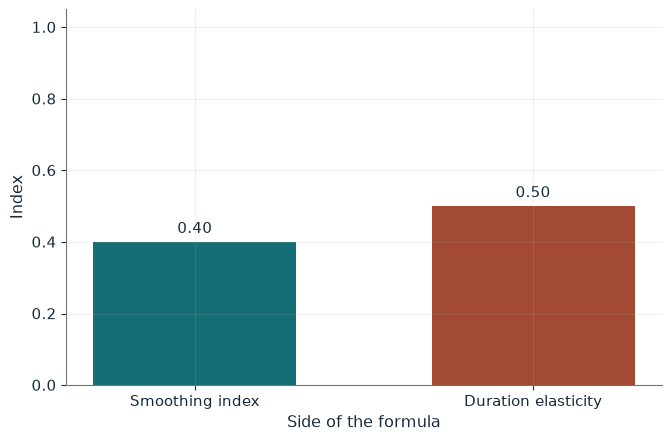

Consumption drop     20%
Smoothing index      0.40
Duration elasticity  0.50
Verdict              Do not raise

Worked steps:
  1. Drop = (3,000 - 2,400) / 3,000 = 0.20
  2. Smoothing index = 2 x 0.20 = 0.40
  3. Elasticity = ((10.5 - 10) / 10) / 0.10 = 0.50
  4. 0.40 against 0.50: do not raise

Hypothetical teaching values, not estimates from a real program. Consumption falls 20% on unemployment, so with risk aversion 2 the smoothing index is 2 x 0.20 = 0.40. A 10 percent benefit rise lengthens duration to 10.5 weeks, an elasticity of 0.50. In this local comparison the behavioral cost exceeds the smoothing gain, pointing against a higher benefit.


In [2]:
show(baily_picture(gamma=2, cu=2400, d1=10.5))

Change one input, `cu`, and hold the others at the book's values:

In [3]:
sweep(baily_picture, 'cu', [2100, 2400], {'gamma': 2, 'd1': 10.5}, ['Smoothing index', 'Duration elasticity', 'Verdict'])

cu | Smoothing index | Duration elasticity | Verdict
2100 | 0.60 | 0.50 | Raise
2400 | 0.40 | 0.50 | Do not raise


At 2,400 the smoothing index 0.40 is below the elasticity 0.50, pointing against a raise. For a claimant at 2,100 the index is 0.60 and the ranking reverses.

## 2. Ordeal mechanism: screening the right or wrong people

Hypothetical values: 100 high-need households value the package at 180, 100 low-need at 80; it costs 120.

$$B_i-c_i(z)\geq 0$$

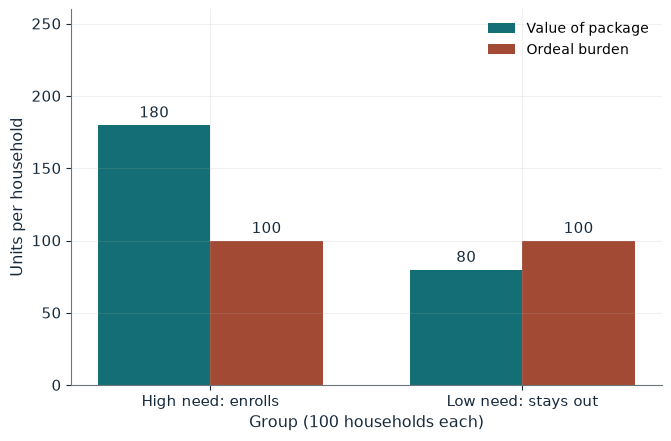

High-need net value  80
Low-need net value   -20
Households enrolled  100
Transfers            12,000
Ordeal cost borne    10,000

Worked steps:
  1. High need: 180 - 100 = 80; low need: 80 - 100 = -20
  2. Transfers = 100 x 120 = 12,000
  3. Ordeal cost = 100 x 100 = 10,000

Hypothetical teaching values, not estimates from a real program. With burdens of 100 on high-need and 100 on low-need households, net values are 180 - 100 = 80 and 80 - 100 = -20, so the ordeal screens as intended. Transfers are 12,000 and recipients bear 10,000 of ordeal cost.


In [4]:
show(ordeal_picture(ch=100, cl=100))

Change one input, `ch`, and hold the others at the book's values:

In [5]:
sweep(ordeal_picture, 'ch', [60, 100, 190], {'cl': 60}, ['Households enrolled', 'Transfers', 'Ordeal cost borne'])

ch | Households enrolled | Transfers | Ordeal cost borne
60 | 200 | 24,000 | 12,000
100 | 200 | 24,000 | 16,000
190 | 100 | 12,000 | 6,000


A uniform burden of 100 admits only the high-need group: transfers 12,000, ordeal cost 10,000. With 190 on the needy and 60 on others, the ordeal admits the wrong group.

## 3. Akerlof tagging: tags, errors and target receipts

Hypothetical values: 400 constrained and 600 other adults; tagged adults get 8,000, against 4,000 to all under the income-only rule. The chapter's arithmetic: $0.75(400)=300$ and $0.10(600)=60$.

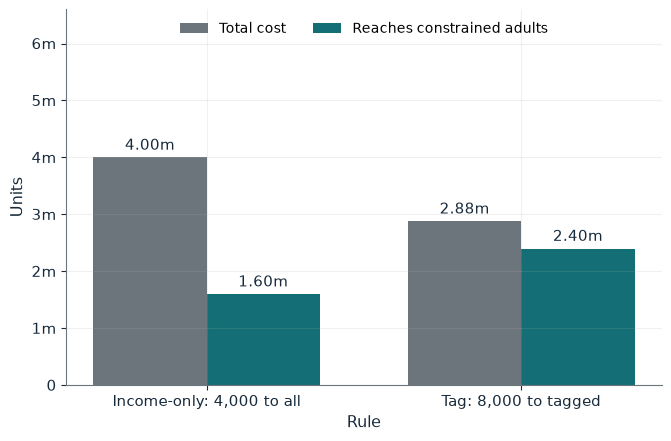

True positives              300
False positives             60
Tagged                      360
Tag cost                    2,880,000
Target receipts             2,400,000
Cost change vs income-only  -1,120,000

Worked steps:
  1. True positives = 0.75 x 400 = 300; false positives = 0.10 x 600 = 60
  2. Cost = 360 x 8,000 = 2,880,000
  3. Target receipts = 300 x 8,000 = 2,400,000
  4. Income-only: 1,000 x 4,000 = 4,000,000, of which 400 x 4,000 = 1,600,000 reaches the target

Hypothetical teaching values, not estimates from a real program. The tag finds 0.75 x 400 = 300 constrained adults and wrongly admits 0.10 x 600 = 60 others. Paying 8,000 to 360 people costs 2,880,000, of which 2,400,000 reaches the target, against 4,000,000 and 1,600,000 under the income-only rule.


In [6]:
show(tagging_picture(tpr=0.75, fpr=0.10))

Change one input, `fpr`, and hold the others at the book's values:

In [7]:
sweep(tagging_picture, 'fpr', [0.1, 0.25, 0.4], {'tpr': 0.75}, ['Tagged', 'Tag cost', 'Target receipts'])

fpr | Tagged | Tag cost | Target receipts
0.1 | 360 | 2,880,000 | 2,400,000
0.25 | 450 | 3,600,000 | 2,400,000
0.4 | 540 | 4,320,000 | 2,400,000


The tag pays 360 people 2,880,000, of which 2,400,000 reaches the target, against 4,000,000 and 1,600,000. At a 40 percent false-positive rate cost rises to 4,320,000 with no gain for the target.

## 4. Public-insurance crowd-out: how much enrollment is new coverage

Hypothetical values: 300 children switch from employer plans, 60 from individual plans and 320 enroll from the uninsured.

$$G=300+60+320=680$$

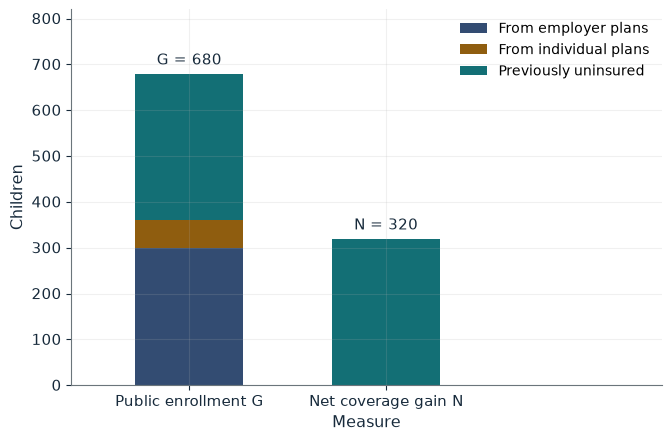

Public enrollment G   680
Private loss P        360
Net gain N            320
Crowd-out P / G       0.529
Net gain per entrant  0.471

Worked steps:
  1. G = 300 + 60 + 320 = 680
  2. P = 300 + 60 = 360
  3. N = 680 - 360 = 320
  4. Crowd-out = 360 / 680 = 0.529

Hypothetical teaching values, not estimates from a real program. Public enrollment is G = 300 + 60 + 320 = 680, of which 360 left private plans, so net coverage rises by N = 320 and crowd-out is 360 / 680 = 0.529 (52.9%). Public enrollment alone would hide the displaced private coverage.


In [8]:
show(crowd_picture(emp=300, ind=60, unin=320))

Change one input, `emp`, and hold the others at the book's values:

In [9]:
sweep(crowd_picture, 'emp', [180, 300], {'ind': 60, 'unin': 320}, ['Public enrollment G', 'Net gain N', 'Crowd-out P / G'])

emp | Public enrollment G | Net gain N | Crowd-out P / G
180 | 560 | 320 | 0.429
300 | 680 | 320 | 0.529


G = 680, P = 360, N = 320 and crowd-out 0.529. Fewer switchers lower crowd-out, but the net gain stays 320, set by uninsured take-up.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

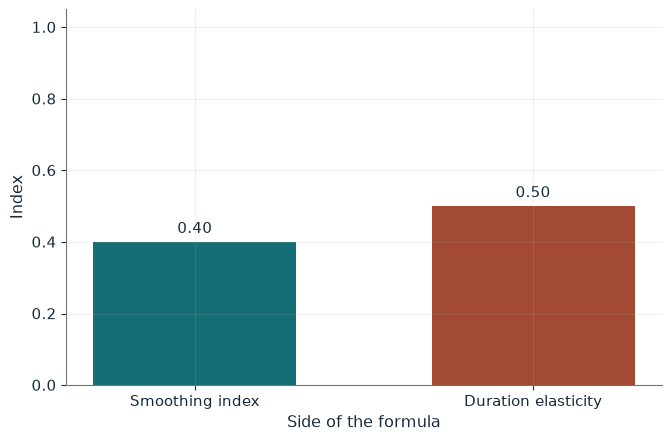

Consumption drop     20%
Smoothing index      0.40
Duration elasticity  0.50
Verdict              Do not raise

Worked steps:
  1. Drop = (3,000 - 2,400) / 3,000 = 0.20
  2. Smoothing index = 2 x 0.20 = 0.40
  3. Elasticity = ((10.5 - 10) / 10) / 0.10 = 0.50
  4. 0.40 against 0.50: do not raise

Hypothetical teaching values, not estimates from a real program. Consumption falls 20% on unemployment, so with risk aversion 2 the smoothing index is 2 x 0.20 = 0.40. A 10 percent benefit rise lengthens duration to 10.5 weeks, an elasticity of 0.50. In this local comparison the behavioral cost exceeds the smoothing gain, pointing against a higher benefit.


In [10]:
show(baily_picture(gamma=2, cu=2400, d1=10.5))

## Practice

**1.** With gamma = 1, consumption 2,100 and duration 10.5, which side of the formula is larger?

<details><summary>Answer</summary>

Smoothing 1 x 0.30 = 0.30 against 0.50, so do not raise.

</details>

**2.** With a hit rate of 0.90 and a false-positive rate of 0.25, what are the tag's cost and target receipts?

<details><summary>Answer</summary>

360 + 150 = 510 tagged; cost 4,080,000; receipts 360 x 8,000 = 2,880,000.

</details>

**3.** With switchers 300 and 60 and uninsured take-up 200, what is crowd-out?

<details><summary>Answer</summary>

G = 560, P = 360, N = 200; 360 / 560 = 0.643.

</details>